## **IT41033 - Nature Inspired Algorithms**
### **Lightweight Machine Learning Model for Early Diabetes Prediction**
#### **Group Members**
###### **Member 1 - R G S M Rathwella - ITBIN-2313-0092**
###### **Member 2 - R G G M N Rajapaksha - ITBIN-2313-0088**
###### **Member 3 - E N S Wijerathne - ITBIN-2313-0128**
###### **Member 3 - D B Senarathna - ITBIN-2313-0105**

#### Responsible: Member 1
### Dataset
PIMA Indians Diabetes Dataset
### Models
1. Logistic Regression
2. Decision Tree
3. Gaussian Naive Bayes
4. Random Forest

## Problem Statement

Diabetes is often diagnosed only after serious health complications have
developed. Machine-learning models can analyse routine clinical measurements
and support early diabetes screening.

This project aims to develop and compare lightweight classification models
using the PIMA Indians Diabetes Dataset. The selected models will be evaluated
based on their predictive performance, reliability, model size and inference
speed.



## Research Questions

1. Which clinical attributes provide the strongest predictive power for
   diabetes prediction?

2. Can lightweight classifiers achieve reliable diabetes-prediction
   performance?

3. Which model provides the best balance between accuracy, recall, model size
   and prediction speed?

## Objectives

1. Collect and understand the PIMA Indians Diabetes Dataset.
2. Identify missing, invalid, duplicate and unusual values.
3. Clean and normalize the clinical attributes.
4. Select the most useful features using correlation analysis and RFE.
5. Train Logistic Regression, Decision Tree and Gaussian Naive Bayes models.
6. Train a Random Forest model as the comparison baseline.
7. Evaluate the models using accuracy, precision, recall, F1-score and ROC-AUC.
8. Apply cross-validation and hyperparameter tuning.
9. Select the best-performing lightweight model.
10. Measure the selected model's size and inference time.

# Step 1: Project setup and dataset collection
Import the required libraries

In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import RFE

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    roc_curve
)

print("Libraries imported successfully")

Libraries imported successfully


Upload and load the dataset

In [34]:
df = pd.read_csv("/content/diabetes.csv")

print("Dataset loaded successfully")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully
Dataset shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


Confirm the columns

In [35]:
print(df.columns.tolist())

['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']


##### Responsible: Member 2
# Step 2: Data Understanding and Exploration

This section examines the dataset structure, data types, descriptive statistics,
class distribution, missing values, invalid zero values, duplicates and outliers.

In [36]:
# Display dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


### Descriptive Statistics

Descriptive statistics are used to understand the distribution, average,
minimum, maximum and variation of each clinical attribute.

In [37]:
# Display descriptive statistics
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


Missing Value Check

The dataset is checked for standard missing values represented as NaN.
Invalid zero measurements will be examined separately.

In [38]:
# Check standard missing values
missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

print("\nTotal missing values:", missing_values.sum())

Missing values in each column:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Total missing values: 0


Invalid Zero Value Analysis

Although the dataset contains no standard NaN values, some clinical attributes
use zero to represent unavailable or missing measurements.

Zero is considered invalid for Glucose, BloodPressure, SkinThickness, Insulin
and BMI. A zero value is valid for Pregnancies, so it will not be treated as
missing.

In [39]:
# Columns where zero represents an invalid or missing measurement
invalid_zero_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

# Count invalid zero values
invalid_zero_counts = (df[invalid_zero_columns] == 0).sum()

print("Invalid zero values in clinical columns:")
print(invalid_zero_counts)

print("\nTotal invalid zero values:", invalid_zero_counts.sum())

Invalid zero values in clinical columns:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

Total invalid zero values: 652


Duplicate Record Check

Duplicate patient records can produce biased model results. Therefore, the
dataset is checked for completely duplicated rows before preprocessing.

In [40]:
# Count completely duplicated rows
duplicate_count = df.duplicated().sum()

print("Number of duplicate records:", duplicate_count)

Number of duplicate records: 0


Target Class Distribution

The Outcome column represents the diabetes classification:

- 0 = No diabetes
- 1 = Diabetes

The class distribution is examined to identify whether the dataset is balanced
or imbalanced.

Outcome counts:
Outcome
0    500
1    268
Name: count, dtype: int64

Outcome percentages:
Outcome
0    65.1
1    34.9
Name: proportion, dtype: float64


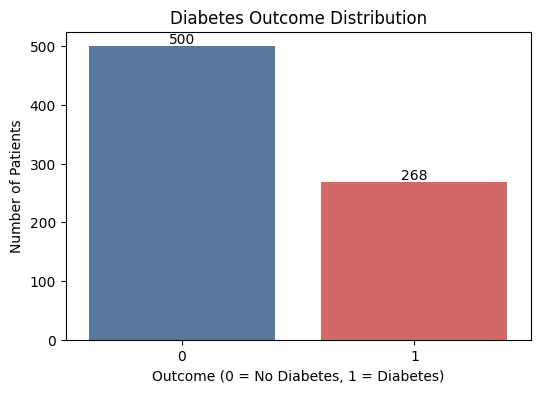

In [41]:
# Count and calculate the percentage of each outcome
outcome_counts = df["Outcome"].value_counts().sort_index()
outcome_percentages = (
    df["Outcome"].value_counts(normalize=True).sort_index() * 100
)

print("Outcome counts:")
print(outcome_counts)

print("\nOutcome percentages:")
print(outcome_percentages.round(2))

# Visualize the class distribution
plt.figure(figsize=(6, 4))

ax = sns.countplot(
    data=df,
    x="Outcome",
    hue="Outcome",
    palette=["#4C78A8", "#E45756"],
    legend=False
)

plt.title("Diabetes Outcome Distribution")
plt.xlabel("Outcome (0 = No Diabetes, 1 = Diabetes)")
plt.ylabel("Number of Patients")

for container in ax.containers:
    ax.bar_label(container)

plt.show()

Feature Distribution Analysis

Histograms are used to examine the distribution, spread and skewness of each
clinical attribute. This helps identify unusual values and determine whether
feature scaling or additional preprocessing is required.

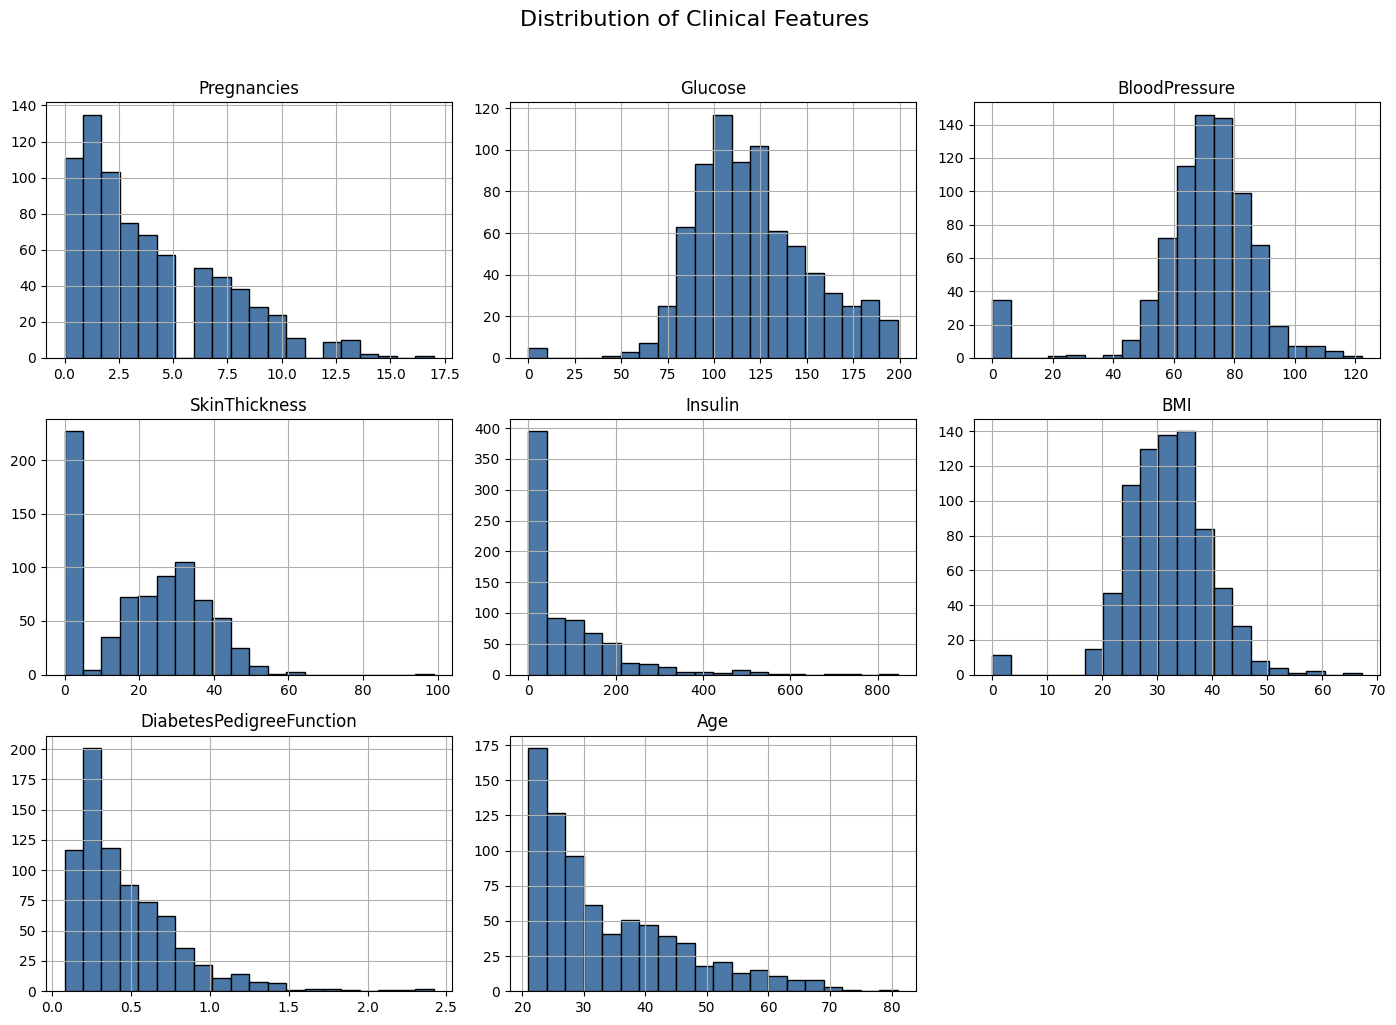

In [42]:
# Plot distributions of all clinical features
feature_columns = df.drop(columns=["Outcome"]).columns

df[feature_columns].hist(
    figsize=(14, 10),
    bins=20,
    color="#4C78A8",
    edgecolor="black"
)

plt.suptitle(
    "Distribution of Clinical Features",
    fontsize=16,
    y=1.02
)

plt.tight_layout()
plt.show()

Correlation Analysis

A correlation heatmap is used to examine the relationships between clinical
features and the diabetes Outcome. Features with stronger relationships to
Outcome may provide greater predictive value.

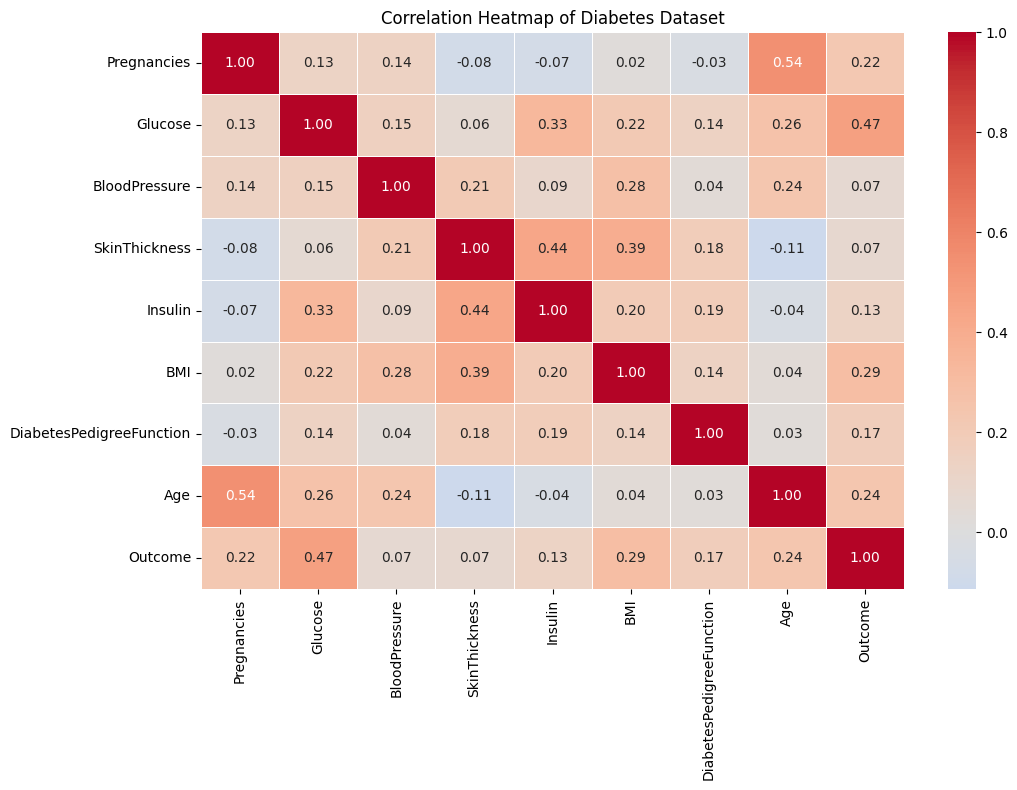

Feature correlations with Outcome:
Glucose                     0.466581
BMI                         0.292695
Age                         0.238356
Pregnancies                 0.221898
DiabetesPedigreeFunction    0.173844
Insulin                     0.130548
SkinThickness               0.074752
BloodPressure               0.065068
Name: Outcome, dtype: float64


In [43]:
# Calculate the correlation matrix
correlation_matrix = df.corr()

# Display the correlation heatmap
plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5,
    center=0
)

plt.title("Correlation Heatmap of Diabetes Dataset")
plt.tight_layout()
plt.show()

# Display correlations with Outcome separately
outcome_correlations = (
    correlation_matrix["Outcome"]
    .drop("Outcome")
    .sort_values(ascending=False)
)

print("Feature correlations with Outcome:")
print(outcome_correlations)

Outlier Analysis

Boxplots are used to identify values located far outside the typical range of
each clinical feature. These values will be reviewed during preprocessing
instead of being removed automatically.

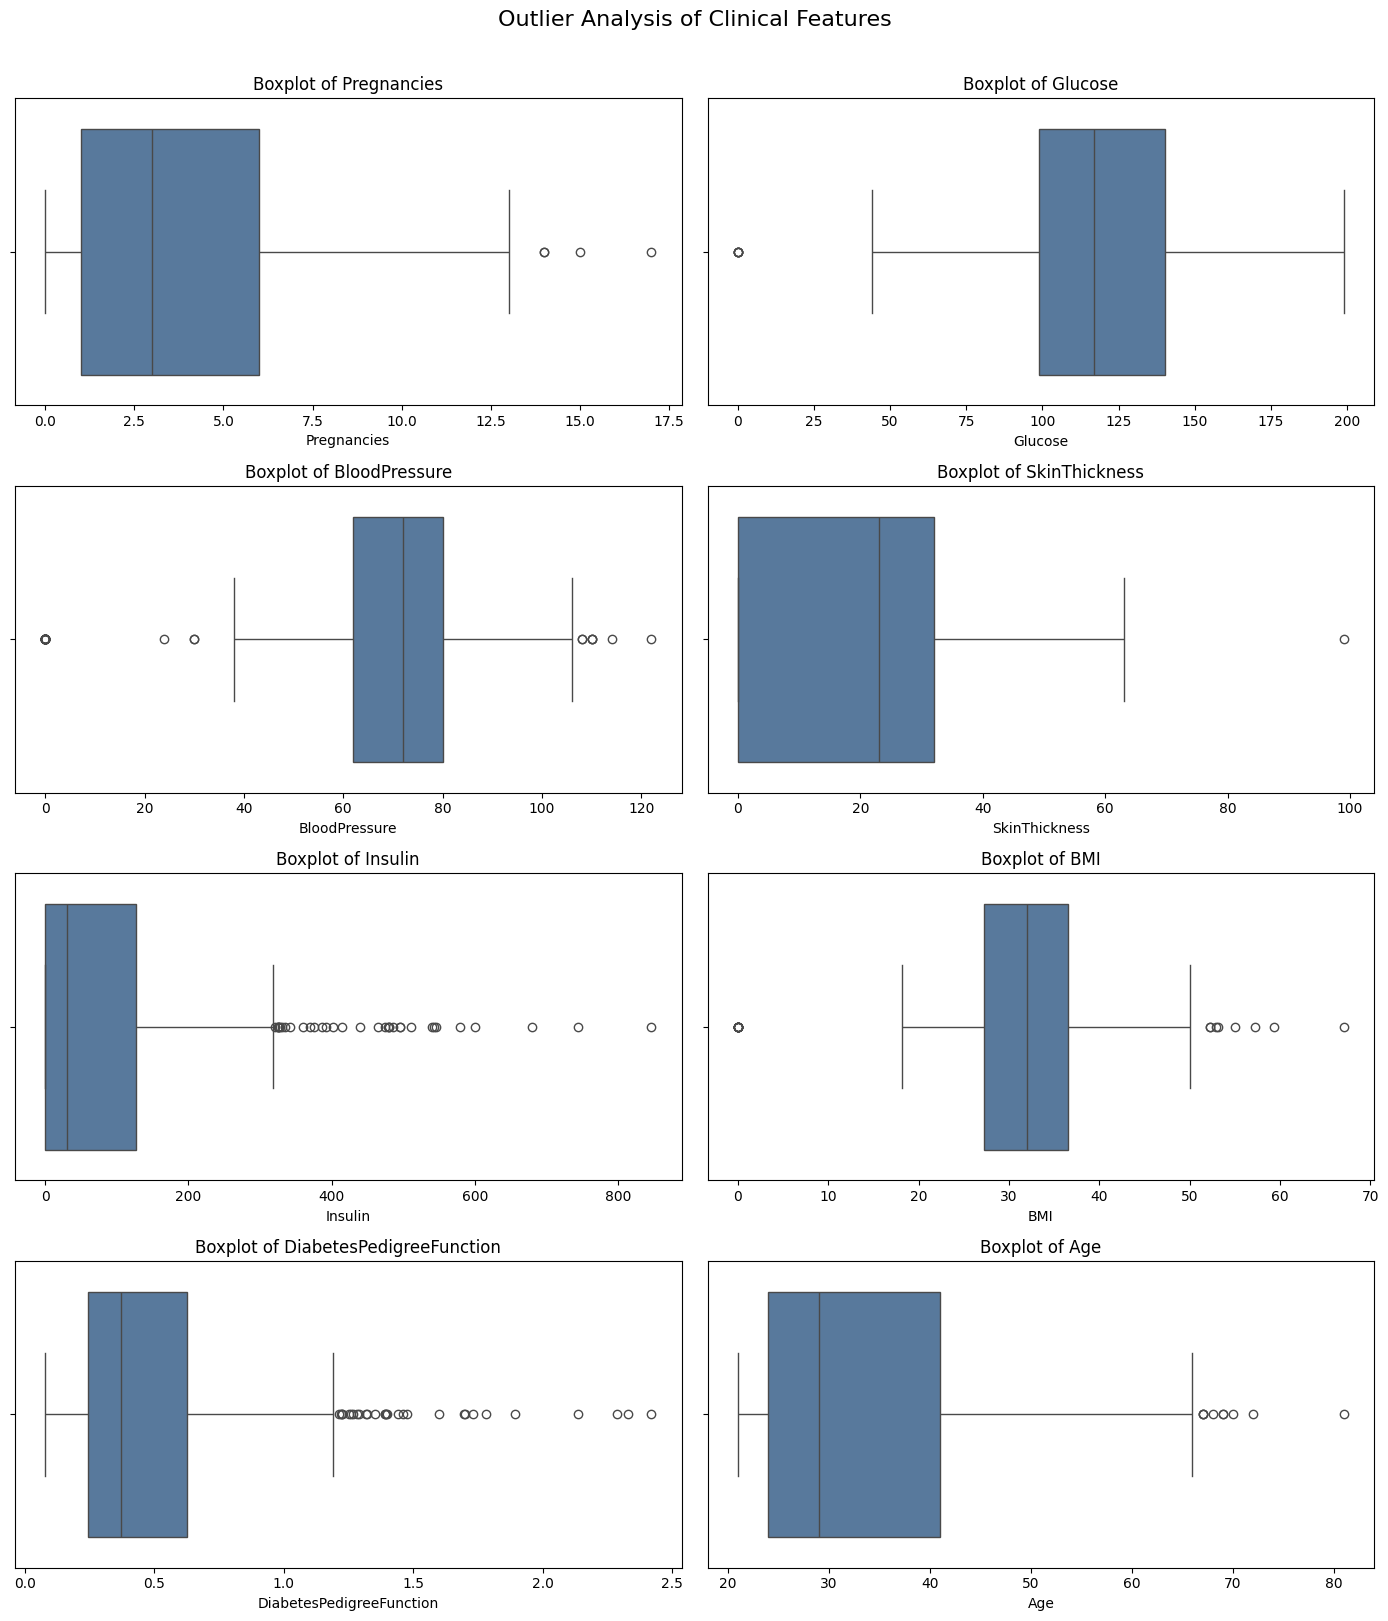

In [44]:
# Create individual boxplots for all clinical features
feature_columns = df.drop(columns=["Outcome"]).columns

fig, axes = plt.subplots(4, 2, figsize=(14, 16))
axes = axes.flatten()

for index, column in enumerate(feature_columns):
    sns.boxplot(
        x=df[column],
        ax=axes[index],
        color="#4C78A8"
    )

    axes[index].set_title(f"Boxplot of {column}")
    axes[index].set_xlabel(column)

plt.suptitle(
    "Outlier Analysis of Clinical Features",
    fontsize=16,
    y=1.01
)

plt.tight_layout()
plt.show()

Exploratory Data Analysis Summary

The dataset contains 768 patient records and nine numerical columns, including
eight clinical features and one binary target variable.

No standard NaN values or duplicate records were identified. However, 652
invalid zero measurements were found across Glucose, BloodPressure,
SkinThickness, Insulin and BMI. Insulin and SkinThickness contained the highest
numbers of invalid zero values.

The target variable showed a moderate class imbalance, with 500 non-diabetic
patients (65.1%) and 268 diabetic patients (34.9%).

Glucose showed the strongest positive correlation with diabetes Outcome,
followed by BMI, Age and Pregnancies. Several features, particularly Insulin,
DiabetesPedigreeFunction, Age and Pregnancies, showed right-skewed
distributions and possible outliers.

These findings indicate that the data requires invalid-zero replacement,
median imputation, feature scaling and feature-selection analysis before model
training.

##### Responsible: Member 3
# Step 3: Data Preprocessing

This section prepares the dataset for model training. Invalid zero measurements
will be converted into missing values, followed by train-test splitting,
median imputation, normalization and feature selection.

The original dataframe will be preserved, and preprocessing will be performed
using a separate working copy.

In [45]:
# Create a separate copy for preprocessing
df_clean = df.copy()

# Columns where zero represents an invalid measurement
invalid_zero_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

# Convert invalid zero values into NaN
df_clean[invalid_zero_columns] = (
    df_clean[invalid_zero_columns].replace(0, np.nan)
)

# Check the new missing-value counts
print("Missing values after converting invalid zeros to NaN:")
print(df_clean.isnull().sum())

print("\nTotal missing values:", df_clean.isnull().sum().sum())

Missing values after converting invalid zeros to NaN:
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64

Total missing values: 652


Feature-Target Separation and Train-Test Split

The eight clinical attributes are separated from the Outcome target. The data
is divided into 80% training data and 20% testing data.

Stratified splitting is used to preserve the original proportion of diabetic
and non-diabetic patients in both sets.

In [46]:
# Separate clinical features and target
X = df_clean.drop(columns=["Outcome"])
y = df_clean["Outcome"]

# Create stratified 80% training and 20% testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Full feature dataset:", X.shape)
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

print("\nTraining Outcome percentages:")
print((y_train.value_counts(normalize=True).sort_index() * 100).round(2))

print("\nTesting Outcome percentages:")
print((y_test.value_counts(normalize=True).sort_index() * 100).round(2))

Full feature dataset: (768, 8)
Training features: (614, 8)
Testing features: (154, 8)
Training target: (614,)
Testing target: (154,)

Training Outcome percentages:
Outcome
0    65.15
1    34.85
Name: proportion, dtype: float64

Testing Outcome percentages:
Outcome
0    64.94
1    35.06
Name: proportion, dtype: float64


Median Imputation

Invalid measurements represented as NaN are replaced using median values.

The imputer is fitted only on the training data to prevent test-data
information from influencing model training. The learned training medians are
then applied to both training and testing datasets.

In [47]:
# Create the median imputer
imputer = SimpleImputer(strategy="median")

# Learn medians from training data and transform both sets
X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

# Convert the results back into dataframes
X_train_imputed = pd.DataFrame(
    X_train_imputed,
    columns=X_train.columns,
    index=X_train.index
)

X_test_imputed = pd.DataFrame(
    X_test_imputed,
    columns=X_test.columns,
    index=X_test.index
)

# Display the median used for each feature
imputation_values = pd.Series(
    imputer.statistics_,
    index=X_train.columns,
    name="Training Median"
)

print("Median values learned from the training data:")
print(imputation_values)

print("\nMissing values remaining in training data:")
print(X_train_imputed.isnull().sum().sum())

print("Missing values remaining in testing data:")
print(X_test_imputed.isnull().sum().sum())

Median values learned from the training data:
Pregnancies                   3.0000
Glucose                     117.0000
BloodPressure                72.0000
SkinThickness                29.0000
Insulin                     125.0000
BMI                          32.4000
DiabetesPedigreeFunction      0.3825
Age                          29.0000
Name: Training Median, dtype: float64

Missing values remaining in training data:
0
Missing values remaining in testing data:
0


Feature Normalization

The clinical features have different measurement units and numerical ranges.
StandardScaler is used to transform each feature to approximately zero mean and
unit variance.

The scaler is fitted only on the imputed training dataset. The same fitted
scaler is then applied to the testing dataset to prevent data leakage.

In [48]:
# Create

Feature Standardization

The clinical features use different numeric scales. StandardScaler transforms
each feature so that the training data has approximately zero mean and unit
standard deviation.

The scaler is fitted only on the imputed training data. The same learned
transformation is then applied to the testing data to prevent data leakage.

In [49]:
# Create the feature scaler
scaler = StandardScaler()

# Fit on training data and transform both sets
X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

# Convert scaled arrays back into dataframes
X_train_scaled = pd.DataFrame(
    X_train_scaled,
    columns=X_train_imputed.columns,
    index=X_train_imputed.index
)

X_test_scaled = pd.DataFrame(
    X_test_scaled,
    columns=X_test_imputed.columns,
    index=X_test_imputed.index
)

print("First five scaled training records:")
display(X_train_scaled.head())

print("\nAverage of each scaled training feature:")
print(X_train_scaled.mean().round(4))

print("\nStandard deviation of each scaled training feature:")
print(X_train_scaled.std(ddof=0).round(4))

First five scaled training records:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
353,-0.851355,-1.056427,-0.826740,-1.918187,-1.203361,-0.769694,0.310794,-0.792169
711,0.356576,0.144399,0.477772,-0.229874,-1.470195,-0.417714,-0.116439,0.561034
373,-0.549372,-0.556083,-1.152868,1.233330,-0.555335,0.359576,-0.764862,-0.707594
46,-0.851355,0.811525,-1.315932,-0.004766,-0.161437,-0.403048,0.262314,-0.369293
682,-1.153338,-0.889646,-0.663676,1.120776,-0.415565,1.782163,-0.337630,-0.961320



Average of each scaled training feature:
Pregnancies                -0.0
Glucose                    -0.0
BloodPressure               0.0
SkinThickness              -0.0
Insulin                    -0.0
BMI                         0.0
DiabetesPedigreeFunction   -0.0
Age                        -0.0
dtype: float64

Standard deviation of each scaled training feature:
Pregnancies                 1.0
Glucose                     1.0
BloodPressure               1.0
SkinThickness               1.0
Insulin                     1.0
BMI                         1.0
DiabetesPedigreeFunction    1.0
Age                         1.0
dtype: float64


Feature Selection Using Recursive Feature Elimination

Recursive Feature Elimination ranks the clinical attributes according to their
predictive contribution.

Logistic Regression is used as the RFE estimator. RFE is fitted only on the
training data to prevent information leakage. The five highest-ranked features
are selected initially, and different subset sizes will be evaluated later.

In [50]:
# Create the estimator used for RFE
rfe_estimator = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Select the five highest-ranked features
rfe_selector = RFE(
    estimator=rfe_estimator,
    n_features_to_select=5
)

# Fit RFE only using the scaled training data
rfe_selector.fit(X_train_scaled, y_train)

# Create a feature-ranking table
feature_ranking = pd.DataFrame({
    "Feature": X_train_scaled.columns,
    "Selected": rfe_selector.support_,
    "RFE_Rank": rfe_selector.ranking_
}).sort_values(
    by=["RFE_Rank", "Feature"]
).reset_index(drop=True)

print("RFE feature ranking:")
display(feature_ranking)

# Store the selected feature names
selected_features = X_train_scaled.columns[
    rfe_selector.support_
].tolist()

print("\nSelected features:")
print(selected_features)

# Create reduced training and testing datasets
X_train_selected = X_train_scaled[selected_features]
X_test_selected = X_test_scaled[selected_features]

print("\nReduced training data shape:", X_train_selected.shape)
print("Reduced testing data shape:", X_test_selected.shape)

RFE feature ranking:


,Feature,Selected,RFE_Rank
0,Age,True,1
1,BMI,True,1
2,DiabetesPedigreeFunction,True,1
3,Glucose,True,1
4,Pregnancies,True,1
5,Insulin,False,2
6,BloodPressure,False,3
7,SkinThickness,False,4



Selected features:
['Pregnancies', 'Glucose', 'BMI', 'DiabetesPedigreeFunction', 'Age']

Reduced training data shape: (614, 5)
Reduced testing data shape: (154, 5)


##### Responsible: Member 1
# Step 4: Model Training

Four classification models are trained and compared:

1. Logistic Regression
2. Decision Tree
3. Gaussian Naive Bayes
4. Random Forest baseline

The lightweight classifiers use the five features selected through RFE.
Random Forest uses all eight clinical attributes as the full-feature baseline.

## 4.1 Logistic Regression

Logistic Regression is a lightweight probabilistic classification model. It
estimates the probability that a patient belongs to the diabetic class.

The model is trained using the five standardized features selected through RFE.

In [51]:
# Create the Logistic Regression model
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train using the five selected features
logistic_model.fit(
    X_train_selected,
    y_train
)

# Generate class predictions and probabilities
logistic_predictions = logistic_model.predict(
    X_test_selected
)

logistic_probabilities = logistic_model.predict_proba(
    X_test_selected
)[:, 1]

# Display initial training and testing accuracy
logistic_train_accuracy = logistic_model.score(
    X_train_selected,
    y_train
)

logistic_test_accuracy = logistic_model.score(
    X_test_selected,
    y_test
)

print("Logistic Regression trained successfully")
print("Training accuracy:", round(logistic_train_accuracy, 4))
print("Testing accuracy:", round(logistic_test_accuracy, 4))

Logistic Regression trained successfully
Training accuracy: 0.7964
Testing accuracy: 0.7013


##### Responsible: Member 2
### 4.2 Decision Tree

Decision Tree is an interpretable lightweight classification model that predicts
diabetes by learning a series of decision rules from the selected clinical
features.

The initial model is trained without pruning. Its training and testing
performance will later be compared to determine whether pruning is required.

In [52]:
# Create the initial Decision Tree model
decision_tree_model = DecisionTreeClassifier(
    random_state=42
)

# Train using the five selected features
decision_tree_model.fit(
    X_train_selected,
    y_train
)

# Generate predictions and probabilities
decision_tree_predictions = decision_tree_model.predict(
    X_test_selected
)

decision_tree_probabilities = decision_tree_model.predict_proba(
    X_test_selected
)[:, 1]

# Calculate initial training and testing accuracy
decision_tree_train_accuracy = decision_tree_model.score(
    X_train_selected,
    y_train
)

decision_tree_test_accuracy = decision_tree_model.score(
    X_test_selected,
    y_test
)

print("Decision Tree trained successfully")
print("Training accuracy:", round(decision_tree_train_accuracy, 4))
print("Testing accuracy:", round(decision_tree_test_accuracy, 4))
print("Tree depth:", decision_tree_model.get_depth())
print("Number of leaf nodes:", decision_tree_model.get_n_leaves())

Decision Tree trained successfully
Training accuracy: 1.0
Testing accuracy: 0.7013
Tree depth: 15
Number of leaf nodes: 121


##### Responsible: Member 3
### 4.3 Gaussian Naive Bayes

Gaussian Naive Bayes is a lightweight probabilistic classifier based on Bayes'
theorem. It assumes that the clinical features follow Gaussian distributions
within each outcome class.

The model is computationally efficient and suitable for systems with limited
processing power and memory.

In [53]:
# Create the Gaussian Naive Bayes model
naive_bayes_model = GaussianNB()

# Train using the five selected features
naive_bayes_model.fit(
    X_train_selected,
    y_train
)

# Generate predictions and probabilities
naive_bayes_predictions = naive_bayes_model.predict(
    X_test_selected
)

naive_bayes_probabilities = naive_bayes_model.predict_proba(
    X_test_selected
)[:, 1]

# Calculate training and testing accuracy
naive_bayes_train_accuracy = naive_bayes_model.score(
    X_train_selected,
    y_train
)

naive_bayes_test_accuracy = naive_bayes_model.score(
    X_test_selected,
    y_test
)

print("Gaussian Naive Bayes trained successfully")
print("Training accuracy:", round(naive_bayes_train_accuracy, 4))
print("Testing accuracy:", round(naive_bayes_test_accuracy, 4))

Gaussian Naive Bayes trained successfully
Training accuracy: 0.7834
Testing accuracy: 0.7338


##### Responsible: Member 4
### 4.4 Random Forest Baseline

Random Forest combines predictions from multiple decision trees. It is generally
more computationally demanding than the three lightweight classifiers and is
therefore used as the full-feature baseline.

The baseline model is trained using all eight imputed clinical attributes.
Feature scaling is not required because Random Forest makes predictions using
decision-tree thresholds.

In [54]:
# Create the Random Forest baseline model
random_forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train using all eight imputed features
random_forest_model.fit(
    X_train_imputed,
    y_train
)

# Generate predictions and probabilities
random_forest_predictions = random_forest_model.predict(
    X_test_imputed
)

random_forest_probabilities = random_forest_model.predict_proba(
    X_test_imputed
)[:, 1]

# Calculate training and testing accuracy
random_forest_train_accuracy = random_forest_model.score(
    X_train_imputed,
    y_train
)

random_forest_test_accuracy = random_forest_model.score(
    X_test_imputed,
    y_test
)

print("Random Forest baseline trained successfully")
print("Training accuracy:", round(random_forest_train_accuracy, 4))
print("Testing accuracy:", round(random_forest_test_accuracy, 4))
print("Number of trees:", random_forest_model.n_estimators)

Random Forest baseline trained successfully
Training accuracy: 1.0
Testing accuracy: 0.7662
Number of trees: 100


##### Responsible: Member 4
# Step 5: Model Evaluation and Comparison

The four models are evaluated using:

- Training accuracy
- Testing accuracy
- Precision
- Recall
- F1-score
- ROC-AUC

Accuracy measures the overall proportion of correct predictions. Precision
measures the reliability of positive diabetes predictions. Recall measures how
many actual diabetic patients were correctly detected. F1-score balances
precision and recall, while ROC-AUC measures the model's ability to separate
the two outcome classes.

Recall is especially important for diabetes screening because a low recall
means that more diabetic patients are incorrectly classified as non-diabetic.

In [55]:
# Define a common evaluation function
def evaluate_classification_model(
    model_name,
    model,
    training_features,
    testing_features,
    predictions,
    probabilities
):
    return {
        "Model": model_name,
        "Training Accuracy": model.score(
            training_features,
            y_train
        ),
        "Testing Accuracy": accuracy_score(
            y_test,
            predictions
        ),
        "Precision": precision_score(
            y_test,
            predictions,
            zero_division=0
        ),
        "Recall": recall_score(
            y_test,
            predictions,
            zero_division=0
        ),
        "F1-Score": f1_score(
            y_test,
            predictions,
            zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_test,
            probabilities
        )
    }


# Evaluate all four models
initial_results = [
    evaluate_classification_model(
        "Logistic Regression",
        logistic_model,
        X_train_selected,
        X_test_selected,
        logistic_predictions,
        logistic_probabilities
    ),

    evaluate_classification_model(
        "Decision Tree",
        decision_tree_model,
        X_train_selected,
        X_test_selected,
        decision_tree_predictions,
        decision_tree_probabilities
    ),

    evaluate_classification_model(
        "Gaussian Naive Bayes",
        naive_bayes_model,
        X_train_selected,
        X_test_selected,
        naive_bayes_predictions,
        naive_bayes_probabilities
    ),

    evaluate_classification_model(
        "Random Forest",
        random_forest_model,
        X_train_imputed,
        X_test_imputed,
        random_forest_predictions,
        random_forest_probabilities
    )
]

# Create and display the comparison table
initial_results_df = pd.DataFrame(initial_results)

numeric_columns = initial_results_df.columns.drop("Model")
initial_results_df[numeric_columns] = (
    initial_results_df[numeric_columns].round(4)
)

initial_results_df = initial_results_df.sort_values(
    by="ROC-AUC",
    ascending=False
).reset_index(drop=True)

print("Initial model comparison:")
display(initial_results_df)

Initial model comparison:


,Model,Training Accuracy,Testing Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Random Forest,1.0000,0.7662,0.6957,0.5926,0.6400,0.8210
1,Logistic Regression,0.7964,0.7013,0.5870,0.5000,0.5400,0.8102
2,Gaussian Naive Bayes,0.7834,0.7338,0.6226,0.6111,0.6168,0.8017
3,Decision Tree,1.0000,0.7013,0.5800,0.5370,0.5577,0.6635


Confusion Matrix Analysis

Confusion matrices display the number of correct and incorrect predictions made
by each model.

- True Negative: A non-diabetic patient correctly predicted as non-diabetic
- False Positive: A non-diabetic patient incorrectly predicted as diabetic
- False Negative: A diabetic patient incorrectly predicted as non-diabetic
- True Positive: A diabetic patient correctly predicted as diabetic

False negatives are especially important because they represent diabetic
patients who were missed by the model.

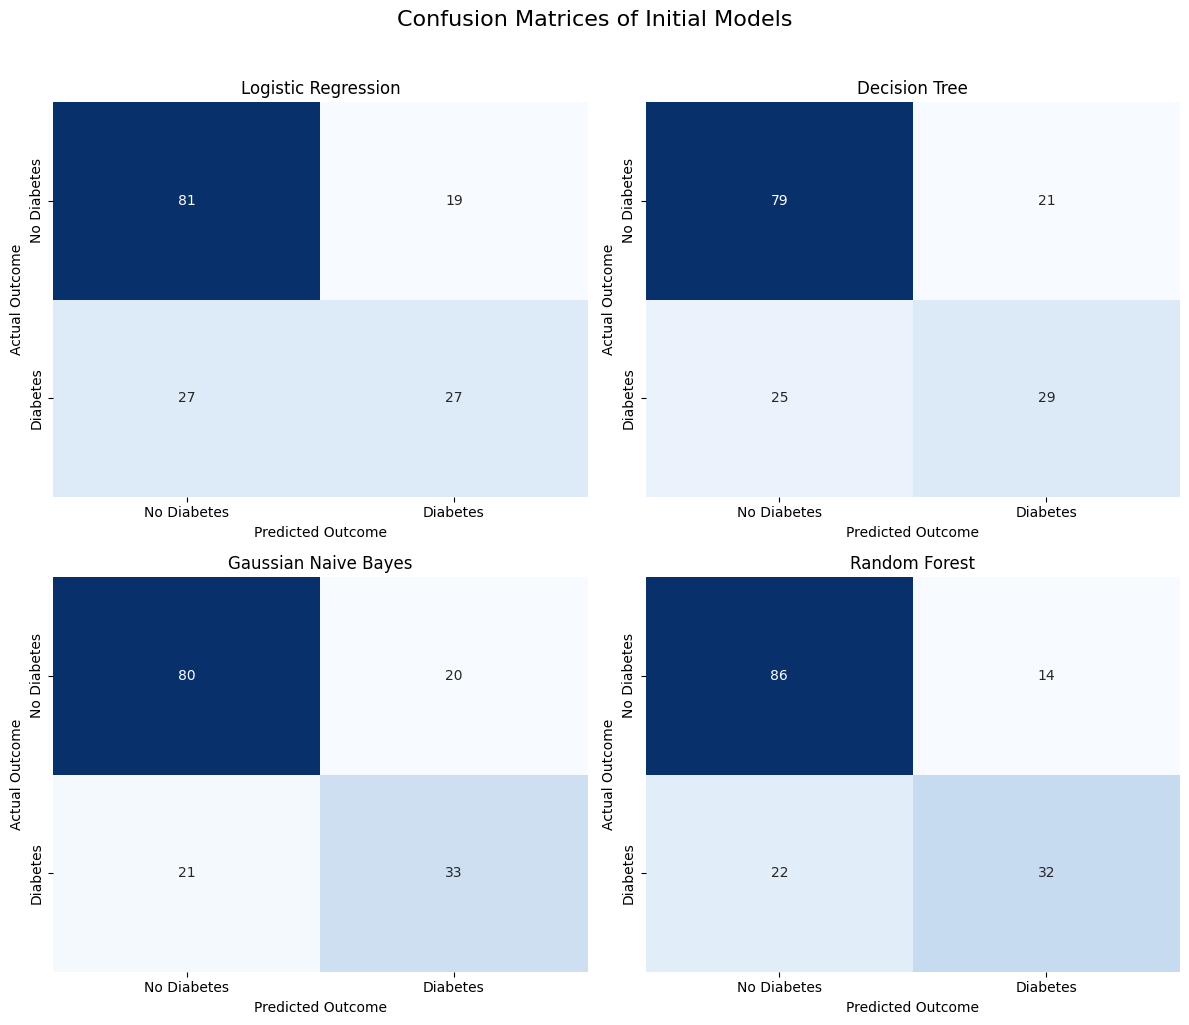

In [56]:
# Store predictions for confusion-matrix comparison
model_predictions = {
    "Logistic Regression": logistic_predictions,
    "Decision Tree": decision_tree_predictions,
    "Gaussian Naive Bayes": naive_bayes_predictions,
    "Random Forest": random_forest_predictions
}

# Create a 2x2 confusion-matrix figure
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for axis, (model_name, predictions) in zip(
    axes,
    model_predictions.items()
):
    matrix = confusion_matrix(y_test, predictions)

    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        ax=axis,
        xticklabels=["No Diabetes", "Diabetes"],
        yticklabels=["No Diabetes", "Diabetes"]
    )

    axis.set_title(model_name)
    axis.set_xlabel("Predicted Outcome")
    axis.set_ylabel("Actual Outcome")

plt.suptitle(
    "Confusion Matrices of Initial Models",
    fontsize=16,
    y=1.02
)

plt.tight_layout()
plt.show()

ROC Curve Comparison

The Receiver Operating Characteristic curve compares each model's true-positive
rate against its false-positive rate across different classification
thresholds.

ROC-AUC values closer to 1.0 indicate better separation between diabetic and
non-diabetic patients.

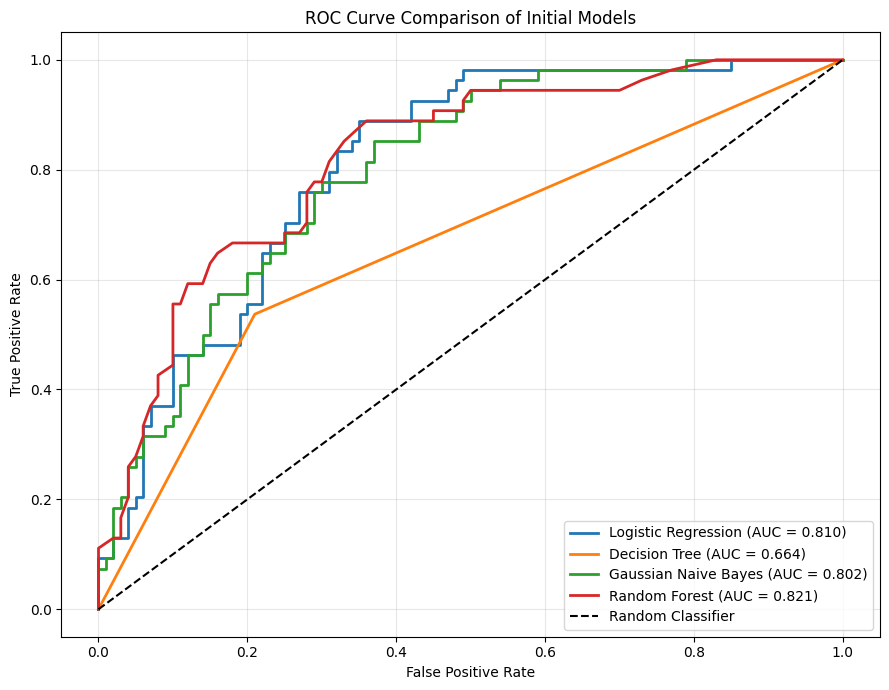

In [57]:
# Store probability predictions for ROC comparison
model_probabilities = {
    "Logistic Regression": logistic_probabilities,
    "Decision Tree": decision_tree_probabilities,
    "Gaussian Naive Bayes": naive_bayes_probabilities,
    "Random Forest": random_forest_probabilities
}

plt.figure(figsize=(9, 7))

for model_name, probabilities in model_probabilities.items():
    false_positive_rate, true_positive_rate, _ = roc_curve(
        y_test,
        probabilities
    )

    auc_score = roc_auc_score(
        y_test,
        probabilities
    )

    plt.plot(
        false_positive_rate,
        true_positive_rate,
        linewidth=2,
        label=f"{model_name} (AUC = {auc_score:.3f})"
    )

# Random-classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="black",
    label="Random Classifier"
)

plt.title("ROC Curve Comparison of Initial Models")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Five-Fold Cross-Validation

Five-fold stratified cross-validation is used to evaluate the stability and
reliability of each model.

The training dataset is divided into five folds. Each model is trained five
times, using four folds for training and one fold for validation. Stratification
preserves the proportion of diabetic and non-diabetic records.

Preprocessing and RFE are included inside each cross-validation pipeline to
prevent information leakage between folds.

In [58]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate

# Create stratified five-fold validation
cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Common scoring metrics
scoring_metrics = {
    "Accuracy": "accuracy",
    "Precision": "precision",
    "Recall": "recall",
    "F1-Score": "f1",
    "ROC-AUC": "roc_auc"
}

# Logistic Regression pipeline
logistic_cv_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("rfe", RFE(
        estimator=LogisticRegression(
            max_iter=1000,
            random_state=42
        ),
        n_features_to_select=5
    )),
    ("model", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Decision Tree pipeline
decision_tree_cv_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("rfe", RFE(
        estimator=LogisticRegression(
            max_iter=1000,
            random_state=42
        ),
        n_features_to_select=5
    )),
    ("model", DecisionTreeClassifier(
        random_state=42
    ))
])

# Gaussian Naive Bayes pipeline
naive_bayes_cv_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("rfe", RFE(
        estimator=LogisticRegression(
            max_iter=1000,
            random_state=42
        ),
        n_features_to_select=5
    )),
    ("model", GaussianNB())
])

# Random Forest full-feature baseline pipeline
random_forest_cv_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

cv_models = {
    "Logistic Regression": logistic_cv_pipeline,
    "Decision Tree": decision_tree_cv_pipeline,
    "Gaussian Naive Bayes": naive_bayes_cv_pipeline,
    "Random Forest": random_forest_cv_pipeline
}

cv_results_summary = []

for model_name, pipeline in cv_models.items():

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv_strategy,
        scoring=scoring_metrics,
        n_jobs=-1
    )

    cv_results_summary.append({
        "Model": model_name,
        "CV Accuracy": scores["test_Accuracy"].mean(),
        "CV Precision": scores["test_Precision"].mean(),
        "CV Recall": scores["test_Recall"].mean(),
        "CV F1-Score": scores["test_F1-Score"].mean(),
        "CV ROC-AUC": scores["test_ROC-AUC"].mean(),
        "Accuracy Std": scores["test_Accuracy"].std()
    })

# Create the cross-validation comparison table
cv_results_df = pd.DataFrame(cv_results_summary)

numeric_columns = cv_results_df.columns.drop("Model")
cv_results_df[numeric_columns] = (
    cv_results_df[numeric_columns].round(4)
)

cv_results_df = cv_results_df.sort_values(
    by="CV ROC-AUC",
    ascending=False
).reset_index(drop=True)

print("Five-fold cross-validation results:")
display(cv_results_df)

Five-fold cross-validation results:


,Model,CV Accuracy,CV Precision,CV Recall,CV F1-Score,CV ROC-AUC,Accuracy Std
0,Logistic Regression,0.7850,0.7552,0.5748,0.6512,0.8445,0.0189
1,Gaussian Naive Bayes,0.7753,0.7188,0.5937,0.6482,0.8427,0.0230
2,Random Forest,0.7606,0.6899,0.5750,0.6258,0.8163,0.0188
3,Decision Tree,0.6499,0.4974,0.5467,0.5200,0.6259,0.0343


##### Responsible: Member 1
# Step 6: Hyperparameter Tuning

Hyperparameter tuning is performed using GridSearchCV and five-fold stratified
cross-validation. Only the training dataset is used during tuning.

ROC-AUC is used as the primary selection metric because it evaluates class
separation across different classification thresholds.

### 6.1 Logistic Regression Tuning

The Logistic Regression regularization strength, penalty, class weighting and
number of selected features are tested. This also helps identify the smallest
feature subset that maintains strong predictive performance.

In [59]:
from sklearn.model_selection import GridSearchCV

# Create a complete Logistic Regression pipeline
logistic_tuning_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("rfe", RFE(
        estimator=LogisticRegression(
            max_iter=1000,
            random_state=42
        )
    )),
    ("model", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Define parameters to test
logistic_parameter_grid = {
    "rfe__n_features_to_select": [3, 4, 5, 6, 7, 8],
    "model__C": [0.01, 0.1, 1, 10, 100],
    "model__penalty": ["l1", "l2"],
    "model__solver": ["liblinear"],
    "model__class_weight": [None, "balanced"]
}

# Create the grid search
logistic_grid_search = GridSearchCV(
    estimator=logistic_tuning_pipeline,
    param_grid=logistic_parameter_grid,
    scoring="roc_auc",
    cv=cv_strategy,
    n_jobs=-1,
    refit=True
)

# Tune using only the raw training data
logistic_grid_search.fit(
    X_train,
    y_train
)

# Store the best complete pipeline
tuned_logistic_model = logistic_grid_search.best_estimator_

# Generate test predictions
tuned_logistic_predictions = tuned_logistic_model.predict(
    X_test
)

tuned_logistic_probabilities = (
    tuned_logistic_model.predict_proba(X_test)[:, 1]
)

# Identify the selected features
logistic_rfe_step = tuned_logistic_model.named_steps["rfe"]

tuned_logistic_features = X_train.columns[
    logistic_rfe_step.support_
].tolist()

# Display results
print("Best Logistic Regression parameters:")
print(logistic_grid_search.best_params_)

print(
    "\nBest cross-validation ROC-AUC:",
    round(logistic_grid_search.best_score_, 4)
)

print("\nSelected features:")
print(tuned_logistic_features)

print(
    "\nTesting accuracy:",
    round(
        accuracy_score(
            y_test,
            tuned_logistic_predictions
        ),
        4
    )
)

print(
    "Testing precision:",
    round(
        precision_score(
            y_test,
            tuned_logistic_predictions
        ),
        4
    )
)

print(
    "Testing recall:",
    round(
        recall_score(
            y_test,
            tuned_logistic_predictions
        ),
        4
    )
)

print(
    "Testing F1-score:",
    round(
        f1_score(
            y_test,
            tuned_logistic_predictions
        ),
        4
    )
)

print(
    "Testing ROC-AUC:",
    round(
        roc_auc_score(
            y_test,
            tuned_logistic_probabilities
        ),
        4
    )
)

Best Logistic Regression parameters:
{'model__C': 0.01, 'model__class_weight': 'balanced', 'model__penalty': 'l2', 'model__solver': 'liblinear', 'rfe__n_features_to_select': 5}

Best cross-validation ROC-AUC: 0.8483

Selected features:
['Pregnancies', 'Glucose', 'BMI', 'DiabetesPedigreeFunction', 'Age']

Testing accuracy: 0.7273
Testing precision: 0.5882
Testing recall: 0.7407
Testing F1-score: 0.6557
Testing ROC-AUC: 0.8128


##### Responsible: Member 2
Decision Tree Tuning and Pruning

The initial Decision Tree reached 100% training accuracy but performed
considerably lower on testing data, indicating overfitting.

Tree depth, minimum split size, minimum leaf size, feature count, splitting
criterion and class weighting are tuned to reduce complexity and improve
generalization. This process acts as pre-pruning.

In [60]:
# Create the complete Decision Tree tuning pipeline
decision_tree_tuning_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("rfe", RFE(
        estimator=LogisticRegression(
            max_iter=1000,
            random_state=42
        )
    )),
    ("model", DecisionTreeClassifier(
        random_state=42
    ))
])

# Define the Decision Tree parameter grid
decision_tree_parameter_grid = {
    "rfe__n_features_to_select": [4, 5, 6, 8],
    "model__criterion": ["gini", "entropy"],
    "model__max_depth": [3, 4, 5, 6, 8],
    "model__min_samples_split": [2, 10, 20],
    "model__min_samples_leaf": [1, 5, 10],
    "model__class_weight": [None, "balanced"]
}

# Create the grid search
decision_tree_grid_search = GridSearchCV(
    estimator=decision_tree_tuning_pipeline,
    param_grid=decision_tree_parameter_grid,
    scoring="roc_auc",
    cv=cv_strategy,
    n_jobs=-1,
    refit=True
)

# Tune using only the training data
decision_tree_grid_search.fit(
    X_train,
    y_train
)

# Store the best complete pipeline
tuned_decision_tree_model = (
    decision_tree_grid_search.best_estimator_
)

# Generate testing predictions and probabilities
tuned_decision_tree_predictions = (
    tuned_decision_tree_model.predict(X_test)
)

tuned_decision_tree_probabilities = (
    tuned_decision_tree_model.predict_proba(X_test)[:, 1]
)

# Access the RFE and Decision Tree steps
decision_tree_rfe_step = (
    tuned_decision_tree_model.named_steps["rfe"]
)

tuned_decision_tree_classifier = (
    tuned_decision_tree_model.named_steps["model"]
)

# Identify selected features
tuned_decision_tree_features = X_train.columns[
    decision_tree_rfe_step.support_
].tolist()

# Display tuning results
print("Best Decision Tree parameters:")
print(decision_tree_grid_search.best_params_)

print(
    "\nBest cross-validation ROC-AUC:",
    round(decision_tree_grid_search.best_score_, 4)
)

print("\nSelected features:")
print(tuned_decision_tree_features)

print(
    "\nTraining accuracy:",
    round(tuned_decision_tree_model.score(X_train, y_train), 4)
)

print(
    "Testing accuracy:",
    round(
        accuracy_score(
            y_test,
            tuned_decision_tree_predictions
        ),
        4
    )
)

print(
    "Testing precision:",
    round(
        precision_score(
            y_test,
            tuned_decision_tree_predictions
        ),
        4
    )
)

print(
    "Testing recall:",
    round(
        recall_score(
            y_test,
            tuned_decision_tree_predictions
        ),
        4
    )
)

print(
    "Testing F1-score:",
    round(
        f1_score(
            y_test,
            tuned_decision_tree_predictions
        ),
        4
    )
)

print(
    "Testing ROC-AUC:",
    round(
        roc_auc_score(
            y_test,
            tuned_decision_tree_probabilities
        ),
        4
    )
)

print(
    "Pruned tree depth:",
    tuned_decision_tree_classifier.get_depth()
)

print(
    "Pruned leaf nodes:",
    tuned_decision_tree_classifier.get_n_leaves()
)

Best Decision Tree parameters:
{'model__class_weight': 'balanced', 'model__criterion': 'gini', 'model__max_depth': 3, 'model__min_samples_leaf': 10, 'model__min_samples_split': 2, 'rfe__n_features_to_select': 5}

Best cross-validation ROC-AUC: 0.7963

Selected features:
['Pregnancies', 'Glucose', 'BMI', 'DiabetesPedigreeFunction', 'Age']

Training accuracy: 0.728
Testing accuracy: 0.6818
Testing precision: 0.5287
Testing recall: 0.8519
Testing F1-score: 0.6525
Testing ROC-AUC: 0.784
Pruned tree depth: 3
Pruned leaf nodes: 8


##### Responsible: Member 3
Gaussian Naive Bayes Tuning

Gaussian Naive Bayes has fewer hyperparameters than the other classifiers.
The variance-smoothing value and number of selected features are tuned.

Variance smoothing improves numerical stability by adding a small value to the
estimated feature variances.

In [61]:
# Create the complete Gaussian Naive Bayes tuning pipeline
naive_bayes_tuning_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("rfe", RFE(
        estimator=LogisticRegression(
            max_iter=1000,
            random_state=42
        )
    )),
    ("model", GaussianNB())
])

# Define the Gaussian Naive Bayes parameter grid
naive_bayes_parameter_grid = {
    "rfe__n_features_to_select": [3, 4, 5, 6, 7, 8],
    "model__var_smoothing": np.logspace(
        -12,
        -6,
        13
    )
}

# Create the grid search
naive_bayes_grid_search = GridSearchCV(
    estimator=naive_bayes_tuning_pipeline,
    param_grid=naive_bayes_parameter_grid,
    scoring="roc_auc",
    cv=cv_strategy,
    n_jobs=-1,
    refit=True
)

# Tune using only the training data
naive_bayes_grid_search.fit(
    X_train,
    y_train
)

# Store the best complete pipeline
tuned_naive_bayes_model = (
    naive_bayes_grid_search.best_estimator_
)

# Generate test predictions and probabilities
tuned_naive_bayes_predictions = (
    tuned_naive_bayes_model.predict(X_test)
)

tuned_naive_bayes_probabilities = (
    tuned_naive_bayes_model.predict_proba(X_test)[:, 1]
)

# Identify selected features
naive_bayes_rfe_step = (
    tuned_naive_bayes_model.named_steps["rfe"]
)

tuned_naive_bayes_features = X_train.columns[
    naive_bayes_rfe_step.support_
].tolist()

# Display tuning results
print("Best Gaussian Naive Bayes parameters:")
print(naive_bayes_grid_search.best_params_)

print(
    "\nBest cross-validation ROC-AUC:",
    round(naive_bayes_grid_search.best_score_, 4)
)

print("\nSelected features:")
print(tuned_naive_bayes_features)

print(
    "\nTraining accuracy:",
    round(tuned_naive_bayes_model.score(X_train, y_train), 4)
)

print(
    "Testing accuracy:",
    round(
        accuracy_score(
            y_test,
            tuned_naive_bayes_predictions
        ),
        4
    )
)

print(
    "Testing precision:",
    round(
        precision_score(
            y_test,
            tuned_naive_bayes_predictions
        ),
        4
    )
)

print(
    "Testing recall:",
    round(
        recall_score(
            y_test,
            tuned_naive_bayes_predictions
        ),
        4
    )
)

print(
    "Testing F1-score:",
    round(
        f1_score(
            y_test,
            tuned_naive_bayes_predictions
        ),
        4
    )
)

print(
    "Testing ROC-AUC:",
    round(
        roc_auc_score(
            y_test,
            tuned_naive_bayes_probabilities
        ),
        4
    )
)

Best Gaussian Naive Bayes parameters:
{'model__var_smoothing': np.float64(1e-12), 'rfe__n_features_to_select': 5}

Best cross-validation ROC-AUC: 0.8427

Selected features:
['Pregnancies', 'Glucose', 'BMI', 'DiabetesPedigreeFunction', 'Age']

Training accuracy: 0.7834
Testing accuracy: 0.7338
Testing precision: 0.6226
Testing recall: 0.6111
Testing F1-score: 0.6168
Testing ROC-AUC: 0.8017


##### Responsible: Member 4
Random Forest Tuning

The initial Random Forest reached 100% training accuracy, indicating
overfitting. The number of trees, maximum depth, split requirements, leaf size,
feature sampling and class weighting are tuned.

Random Forest continues to use all eight clinical attributes as the
full-feature baseline.

In [62]:
# Create the complete Random Forest tuning pipeline
random_forest_tuning_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ))
])

# Define the Random Forest parameter grid
random_forest_parameter_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [3, 5, 8, None],
    "model__min_samples_split": [2, 10],
    "model__min_samples_leaf": [1, 5],
    "model__max_features": ["sqrt", "log2", None],
    "model__class_weight": [None, "balanced"]
}

# Create the grid search
random_forest_grid_search = GridSearchCV(
    estimator=random_forest_tuning_pipeline,
    param_grid=random_forest_parameter_grid,
    scoring="roc_auc",
    cv=cv_strategy,
    n_jobs=-1,
    refit=True
)

# Tune using only the training data
random_forest_grid_search.fit(
    X_train,
    y_train
)

# Store the best complete pipeline
tuned_random_forest_model = (
    random_forest_grid_search.best_estimator_
)

# Generate test predictions and probabilities
tuned_random_forest_predictions = (
    tuned_random_forest_model.predict(X_test)
)

tuned_random_forest_probabilities = (
    tuned_random_forest_model.predict_proba(X_test)[:, 1]
)

# Display tuning results
print("Best Random Forest parameters:")
print(random_forest_grid_search.best_params_)

print(
    "\nBest cross-validation ROC-AUC:",
    round(random_forest_grid_search.best_score_, 4)
)

print(
    "\nTraining accuracy:",
    round(tuned_random_forest_model.score(X_train, y_train), 4)
)

print(
    "Testing accuracy:",
    round(
        accuracy_score(
            y_test,
            tuned_random_forest_predictions
        ),
        4
    )
)

print(
    "Testing precision:",
    round(
        precision_score(
            y_test,
            tuned_random_forest_predictions
        ),
        4
    )
)

print(
    "Testing recall:",
    round(
        recall_score(
            y_test,
            tuned_random_forest_predictions
        ),
        4
    )
)

print(
    "Testing F1-score:",
    round(
        f1_score(
            y_test,
            tuned_random_forest_predictions
        ),
        4
    )
)

print(
    "Testing ROC-AUC:",
    round(
        roc_auc_score(
            y_test,
            tuned_random_forest_probabilities
        ),
        4
    )
)

Best Random Forest parameters:
{'model__class_weight': None, 'model__max_depth': 5, 'model__max_features': 'log2', 'model__min_samples_leaf': 5, 'model__min_samples_split': 2, 'model__n_estimators': 100}

Best cross-validation ROC-AUC: 0.8422

Training accuracy: 0.8371
Testing accuracy: 0.7338
Testing precision: 0.6585
Testing recall: 0.5
Testing F1-score: 0.5684
Testing ROC-AUC: 0.8031


##### Responsible: Member 1
Final Tuned-Model Comparison

The tuned versions of all four models are compared using the held-out testing
set and their best five-fold cross-validation ROC-AUC scores.

The final lightweight model will be selected by considering recall, F1-score,
ROC-AUC, model complexity, size and inference speed rather than accuracy alone.

In [63]:
# Define an evaluation function for complete tuned pipelines
def evaluate_tuned_model(
    model_name,
    model,
    predictions,
    probabilities,
    best_cv_auc
):
    return {
        "Model": model_name,
        "Training Accuracy": model.score(
            X_train,
            y_train
        ),
        "Testing Accuracy": accuracy_score(
            y_test,
            predictions
        ),
        "Precision": precision_score(
            y_test,
            predictions,
            zero_division=0
        ),
        "Recall": recall_score(
            y_test,
            predictions,
            zero_division=0
        ),
        "F1-Score": f1_score(
            y_test,
            predictions,
            zero_division=0
        ),
        "Testing ROC-AUC": roc_auc_score(
            y_test,
            probabilities
        ),
        "Best CV ROC-AUC": best_cv_auc
    }


# Evaluate all tuned models
tuned_results = [
    evaluate_tuned_model(
        "Logistic Regression",
        tuned_logistic_model,
        tuned_logistic_predictions,
        tuned_logistic_probabilities,
        logistic_grid_search.best_score_
    ),

    evaluate_tuned_model(
        "Decision Tree",
        tuned_decision_tree_model,
        tuned_decision_tree_predictions,
        tuned_decision_tree_probabilities,
        decision_tree_grid_search.best_score_
    ),

    evaluate_tuned_model(
        "Gaussian Naive Bayes",
        tuned_naive_bayes_model,
        tuned_naive_bayes_predictions,
        tuned_naive_bayes_probabilities,
        naive_bayes_grid_search.best_score_
    ),

    evaluate_tuned_model(
        "Random Forest",
        tuned_random_forest_model,
        tuned_random_forest_predictions,
        tuned_random_forest_probabilities,
        random_forest_grid_search.best_score_
    )
]

# Create the final comparison table
tuned_results_df = pd.DataFrame(tuned_results)

numeric_columns = tuned_results_df.columns.drop("Model")
tuned_results_df[numeric_columns] = (
    tuned_results_df[numeric_columns].round(4)
)

tuned_results_df = tuned_results_df.sort_values(
    by="Best CV ROC-AUC",
    ascending=False
).reset_index(drop=True)

print("Final tuned-model comparison:")
display(tuned_results_df)

Final tuned-model comparison:


,Model,Training Accuracy,Testing Accuracy,Precision,Recall,F1-Score,Testing ROC-AUC,Best CV ROC-AUC
0,Logistic Regression,0.7524,0.7273,0.5882,0.7407,0.6557,0.8128,0.8483
1,Gaussian Naive Bayes,0.7834,0.7338,0.6226,0.6111,0.6168,0.8017,0.8427
2,Random Forest,0.8371,0.7338,0.6585,0.5000,0.5684,0.8031,0.8422
3,Decision Tree,0.7280,0.6818,0.5287,0.8519,0.6525,0.7840,0.7963


# Step 7: Lightweight Model Analysis

The tuned models are compared based on serialized model size and prediction
time.

A lightweight model should maintain reliable predictive performance while
requiring less storage and producing predictions quickly. The complete
pipelines are measured so that preprocessing, feature selection and
classification components are included.

In [64]:
import os
import time
import joblib

# Store all tuned pipelines
final_models = {
    "Logistic Regression": tuned_logistic_model,
    "Decision Tree": tuned_decision_tree_model,
    "Gaussian Naive Bayes": tuned_naive_bayes_model,
    "Random Forest": tuned_random_forest_model
}

resource_results = []

# Number of repeated timing tests
repetitions = 100

for model_name, model in final_models.items():

    # Create a safe filename
    file_name = (
        model_name.lower()
        .replace(" ", "_")
        + "_tuned.pkl"
    )

    # Save the complete pipeline without compression
    joblib.dump(
        model,
        file_name,
        compress=0
    )

    # Calculate model size in kilobytes
    model_size_kb = os.path.getsize(file_name) / 1024

    # Warm-up prediction
    model.predict(X_test)

    # Measure repeated prediction time
    start_time = time.perf_counter()

    for _ in range(repetitions):
        model.predict(X_test)

    end_time = time.perf_counter()

    # Average time for one full test-set prediction
    average_batch_time_ms = (
        (end_time - start_time)
        / repetitions
        * 1000
    )

    # Average time for one patient
    average_patient_time_ms = (
        average_batch_time_ms
        / len(X_test)
    )

    resource_results.append({
        "Model": model_name,
        "Model Size (KB)": model_size_kb,
        "Batch Time (ms)": average_batch_time_ms,
        "Time per Patient (ms)": average_patient_time_ms
    })

# Create the resource comparison table
resource_results_df = pd.DataFrame(resource_results)

resource_results_df[
    [
        "Model Size (KB)",
        "Batch Time (ms)",
        "Time per Patient (ms)"
    ]
] = resource_results_df[
    [
        "Model Size (KB)",
        "Batch Time (ms)",
        "Time per Patient (ms)"
    ]
].round(4)

resource_results_df = resource_results_df.sort_values(
    by="Model Size (KB)"
).reset_index(drop=True)

print("Model size and inference-time comparison:")
display(resource_results_df)

Model size and inference-time comparison:


,Model,Model Size (KB),Batch Time (ms),Time per Patient (ms)
0,Logistic Regression,3.1064,2.7531,0.0179
1,Gaussian Naive Bayes,3.3369,2.8859,0.0187
2,Decision Tree,4.8545,2.7931,0.0181
3,Random Forest,356.4082,29.7571,0.1932


Reduced-Precision Quantization

The selected Logistic Regression pipeline is optimized by converting its
floating-point parameters from 64-bit to 32-bit precision.

The quantized model is compared with the original tuned model based on file
size, accuracy, ROC-AUC and inference time. The optimization is considered
acceptable if the accuracy reduction remains below 3%.

In [65]:
import copy

# Create an independent copy of the tuned model
quantized_logistic_model = copy.deepcopy(
    tuned_logistic_model
)

# Access pipeline components
quantized_imputer = (
    quantized_logistic_model.named_steps["imputer"]
)

quantized_scaler = (
    quantized_logistic_model.named_steps["scaler"]
)

quantized_rfe = (
    quantized_logistic_model.named_steps["rfe"]
)

quantized_classifier = (
    quantized_logistic_model.named_steps["model"]
)

# Convert imputer parameters to float32
quantized_imputer.statistics_ = (
    quantized_imputer.statistics_.astype(np.float32)
)

# Convert scaler parameters to float32
quantized_scaler.mean_ = (
    quantized_scaler.mean_.astype(np.float32)
)

quantized_scaler.scale_ = (
    quantized_scaler.scale_.astype(np.float32)
)

quantized_scaler.var_ = (
    quantized_scaler.var_.astype(np.float32)
)

# Convert RFE estimator parameters to float32
quantized_rfe.estimator_.coef_ = (
    quantized_rfe.estimator_.coef_.astype(np.float32)
)

quantized_rfe.estimator_.intercept_ = (
    quantized_rfe.estimator_.intercept_.astype(np.float32)
)

# Convert final Logistic Regression parameters to float32
quantized_classifier.coef_ = (
    quantized_classifier.coef_.astype(np.float32)
)

quantized_classifier.intercept_ = (
    quantized_classifier.intercept_.astype(np.float32)
)

# Save the original and quantized pipelines
joblib.dump(
    tuned_logistic_model,
    "logistic_regression_original.pkl",
    compress=0
)

joblib.dump(
    quantized_logistic_model,
    "logistic_regression_float32.pkl",
    compress=0
)

# Also save a compressed deployment version
joblib.dump(
    quantized_logistic_model,
    "logistic_regression_final_compressed.pkl",
    compress=3
)

# Generate quantized-model predictions
quantized_predictions = quantized_logistic_model.predict(
    X_test
)

quantized_probabilities = (
    quantized_logistic_model.predict_proba(X_test)[:, 1]
)

# Calculate file sizes
original_size_kb = (
    os.path.getsize(
        "logistic_regression_original.pkl"
    ) / 1024
)

quantized_size_kb = (
    os.path.getsize(
        "logistic_regression_float32.pkl"
    ) / 1024
)

compressed_size_kb = (
    os.path.getsize(
        "logistic_regression_final_compressed.pkl"
    ) / 1024
)

# Measure quantized inference time
quantized_logistic_model.predict(X_test)

start_time = time.perf_counter()

for _ in range(repetitions):
    quantized_logistic_model.predict(X_test)

end_time = time.perf_counter()

quantized_patient_time_ms = (
    ((end_time - start_time) / repetitions) * 1000
    / len(X_test)
)

# Compare original and quantized models
original_accuracy = accuracy_score(
    y_test,
    tuned_logistic_predictions
)

quantized_accuracy = accuracy_score(
    y_test,
    quantized_predictions
)

accuracy_drop_percentage = (
    (original_accuracy - quantized_accuracy) * 100
)

quantization_results = pd.DataFrame([
    {
        "Version": "Original Float64",
        "Size (KB)": original_size_kb,
        "Accuracy": original_accuracy,
        "ROC-AUC": roc_auc_score(
            y_test,
            tuned_logistic_probabilities
        ),
        "Time per Patient (ms)": resource_results_df.loc[
            resource_results_df["Model"]
            == "Logistic Regression",
            "Time per Patient (ms)"
        ].iloc[0]
    },
    {
        "Version": "Quantized Float32",
        "Size (KB)": quantized_size_kb,
        "Accuracy": quantized_accuracy,
        "ROC-AUC": roc_auc_score(
            y_test,
            quantized_probabilities
        ),
        "Time per Patient (ms)": quantized_patient_time_ms
    },
    {
        "Version": "Float32 + Compression",
        "Size (KB)": compressed_size_kb,
        "Accuracy": quantized_accuracy,
        "ROC-AUC": roc_auc_score(
            y_test,
            quantized_probabilities
        ),
        "Time per Patient (ms)": quantized_patient_time_ms
    }
])

numeric_columns = quantization_results.columns.drop("Version")
quantization_results[numeric_columns] = (
    quantization_results[numeric_columns].round(4)
)

print("Quantization comparison:")
display(quantization_results)

print(
    "\nAccuracy drop after quantization:",
    round(accuracy_drop_percentage, 4),
    "%"
)

print(
    "Accuracy-drop requirement satisfied:",
    accuracy_drop_percentage < 3
)

Quantization comparison:


,Version,Size (KB),Accuracy,ROC-AUC,Time per Patient (ms)
0,Original Float64,3.1064,0.7273,0.8128,0.0179
1,Quantized Float32,2.9658,0.7273,0.8128,0.0200
2,Float32 + Compression,1.5176,0.7273,0.8128,0.0200



Accuracy drop after quantization: 0.0 %
Accuracy-drop requirement satisfied: True


# Step 8: Final Prediction Demonstration

The optimized Logistic Regression pipeline is used to predict the diabetes
outcome for an individual patient.

The pipeline accepts all eight original clinical attributes, automatically
applies median imputation, normalization and feature selection, and returns a
predicted class and probability.

This model is intended only for academic screening research and does not
provide a medical diagnosis.

In [66]:
# Load the final optimized deployment model
final_model = joblib.load(
    "logistic_regression_final_compressed.pkl"
)

# Create a reusable patient-prediction function
def predict_diabetes(
    pregnancies,
    glucose,
    blood_pressure,
    skin_thickness,
    insulin,
    bmi,
    diabetes_pedigree_function,
    age
):
    # Create one patient record using all original features
    patient = pd.DataFrame([{
        "Pregnancies": pregnancies,
        "Glucose": glucose,
        "BloodPressure": blood_pressure,
        "SkinThickness": skin_thickness,
        "Insulin": insulin,
        "BMI": bmi,
        "DiabetesPedigreeFunction":
            diabetes_pedigree_function,
        "Age": age
    }])

    # Convert invalid zero measurements into NaN
    invalid_columns = [
        "Glucose",
        "BloodPressure",
        "SkinThickness",
        "Insulin",
        "BMI"
    ]

    patient[invalid_columns] = (
        patient[invalid_columns].replace(0, np.nan)
    )

    # Generate prediction and probability
    predicted_class = final_model.predict(patient)[0]

    diabetes_probability = (
        final_model.predict_proba(patient)[0, 1]
    )

    result_label = (
        "Higher likelihood of diabetes"
        if predicted_class == 1
        else "Lower likelihood of diabetes"
    )

    return {
        "Prediction Class": int(predicted_class),
        "Prediction": result_label,
        "Diabetes Probability":
            f"{diabetes_probability * 100:.2f}%"
    }


# Demonstrate using a sample patient
sample_result = predict_diabetes(
    pregnancies=6,
    glucose=148,
    blood_pressure=72,
    skin_thickness=35,
    insulin=0,
    bmi=33.6,
    diabetes_pedigree_function=0.627,
    age=50
)

print("Final patient prediction:")
for key, value in sample_result.items():
    print(f"{key}: {value}")

print(
    "\nDisclaimer: This output is for academic screening research "
    "only and is not a medical diagnosis."
)

Final patient prediction:
Prediction Class: 1
Prediction: Higher likelihood of diabetes
Diabetes Probability: 71.39%

Disclaimer: This output is for academic screening research only and is not a medical diagnosis.


# Step 9: Save Final Project Outputs

The optimized model and all important result tables are exported into a ZIP
archive for submission, demonstration and future use.

In [67]:
import zipfile
from google.colab import files

# Export result tables
initial_results_df.to_csv(
    "initial_model_results.csv",
    index=False
)

cv_results_df.to_csv(
    "cross_validation_results.csv",
    index=False
)

tuned_results_df.to_csv(
    "tuned_model_results.csv",
    index=False
)

resource_results_df.to_csv(
    "model_resource_comparison.csv",
    index=False
)

quantization_results.to_csv(
    "quantization_results.csv",
    index=False
)

# Save selected-feature information
with open(
    "selected_features.txt",
    "w"
) as feature_file:

    feature_file.write(
        "Final selected features:\n"
    )

    for feature in tuned_logistic_features:
        feature_file.write(f"- {feature}\n")

# Files included in the final package
project_files = [
    "logistic_regression_final_compressed.pkl",
    "logistic_regression_original.pkl",
    "logistic_regression_float32.pkl",
    "initial_model_results.csv",
    "cross_validation_results.csv",
    "tuned_model_results.csv",
    "model_resource_comparison.csv",
    "quantization_results.csv",
    "selected_features.txt"
]

# Create the ZIP archive
zip_filename = (
    "Diabetes_Prediction_Final_Outputs.zip"
)

with zipfile.ZipFile(
    zip_filename,
    "w",
    zipfile.ZIP_DEFLATED
) as zip_file:

    for file_name in project_files:
        zip_file.write(file_name)

print(
    "Final project package created:",
    zip_filename
)

# Download the ZIP package
files.download(zip_filename)

Final project package created: Diabetes_Prediction_Final_Outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Step 10: Results, Discussion and Conclusion

## 10.1 Results

Four machine-learning classifiers were developed using the PIMA Indians
Diabetes Dataset:

1. Logistic Regression
2. Decision Tree
3. Gaussian Naive Bayes
4. Random Forest baseline

The dataset contained 768 patient records, eight clinical features and one
binary Outcome variable. No standard missing values or duplicate records were
identified. However, 652 medically invalid zero measurements were detected in
Glucose, BloodPressure, SkinThickness, Insulin and BMI.

The invalid values were converted into missing values and replaced using
medians learned only from the training dataset. The data was divided into 80%
training and 20% testing sets using stratification.

Recursive Feature Elimination selected five attributes:

- Pregnancies
- Glucose
- BMI
- DiabetesPedigreeFunction
- Age

These features were used by the three lightweight classifiers. Random Forest
used all eight clinical features as the full-feature baseline.

### Initial Model Results

The initial Random Forest produced the highest testing accuracy of 76.62% and
ROC-AUC of 0.8210. However, it achieved 100% training accuracy, indicating
overfitting.

Gaussian Naive Bayes produced the strongest initial lightweight testing
accuracy of 73.38% and recall of 61.11%. Logistic Regression produced a
testing ROC-AUC of 0.8102 but only 50.00% recall at its default classification
threshold.

The unpruned Decision Tree achieved 100% training accuracy and only 70.13%
testing accuracy, showing clear overfitting.

### Cross-Validation Results

Five-fold stratified cross-validation showed that Logistic Regression provided
the strongest overall lightweight performance:

- Cross-validation accuracy: 78.50%
- Cross-validation precision: 75.52%
- Cross-validation recall: 57.48%
- Cross-validation F1-score: 0.6512
- Cross-validation ROC-AUC: 0.8445

Gaussian Naive Bayes produced a similar cross-validation ROC-AUC of 0.8427 and
the highest initial cross-validation recall of 59.37%.

The lightweight Logistic Regression and Gaussian Naive Bayes models matched or
outperformed the Random Forest baseline during cross-validation.

### Tuned Model Results

After hyperparameter tuning, Logistic Regression achieved:

- Testing accuracy: 72.73%
- Precision: 58.82%
- Recall: 74.07%
- F1-score: 0.6557
- Testing ROC-AUC: 0.8128
- Best cross-validation ROC-AUC: 0.8483

The tuned and pruned Decision Tree achieved the highest recall of 85.19%.
Pruning reduced its depth from 15 to 3 and its leaf-node count from 121 to 8.
However, its testing accuracy was 68.18%, and its ROC-AUC was 0.7840.

Gaussian Naive Bayes achieved the highest tuned lightweight testing accuracy
of 73.38%, with a recall of 61.11% and ROC-AUC of 0.8017.

The tuned Random Forest achieved 73.38% testing accuracy and 0.8031 ROC-AUC.
Its training accuracy was reduced from 100% to 83.71%, showing improved
generalization.

## 10.2 Discussion

The results demonstrate that a lightweight classifier can provide performance
comparable to a larger Random Forest baseline while requiring considerably
less storage and prediction time.

Logistic Regression was selected as the final model because it produced the
highest cross-validation ROC-AUC, the highest tuned F1-score, strong recall and
a small model size. It also used only five of the original eight attributes.

Although Gaussian Naive Bayes produced slightly higher testing accuracy,
Logistic Regression provided better recall, F1-score and cross-validation
ROC-AUC. These metrics are particularly important for screening because the
cost of failing to detect a potentially diabetic patient may be greater than
producing a false-positive screening result.

The pruned Decision Tree produced the highest recall. However, its lower
accuracy and ROC-AUC indicate that it generated more false-positive
predictions.

None of the models reached the proposal's target of 80% accuracy on the held-out
testing set. Therefore, the 80% testing-accuracy objective was not achieved.
However, Logistic Regression reached 78.50% average accuracy during
cross-validation and produced a strong cross-validation ROC-AUC of 0.8483.

The difference between held-out testing accuracy and cross-validation
performance may be influenced by the relatively small dataset size, class
imbalance, measurement uncertainty and missing clinical values.

## 10.3 Lightweight Optimization

The tuned Logistic Regression pipeline had an original serialized size of
3.1064 KB and required approximately 0.0179 milliseconds per patient.

The model was converted from 64-bit to 32-bit floating-point precision. The
quantized model maintained identical accuracy and ROC-AUC.

After reduced-precision conversion and compression:

- Final model size: 1.5176 KB
- Size reduction: approximately 51.1%
- Accuracy reduction: 0%
- Final testing accuracy: 72.73%
- Final testing ROC-AUC: 0.8128

The optimization therefore satisfied the requirement of maintaining an
accuracy reduction below 3%.

## 10.4 Limitations

This study has several limitations:

- The PIMA dataset contains only 768 patient records.
- The dataset represents a specific population and may not generalize to all
  demographic groups.
- Several clinical measurements contained large numbers of missing values.
- The dataset has moderate class imbalance.
- The model is intended for screening research rather than clinical diagnosis.
- Independent Sri Lankan clinical data was not available for external
  validation.
- The model's probability output should not be interpreted as a confirmed
  medical diagnosis.

## 10.5 Future Work

Future work could include:

- Validating the model using the CDC Diabetes Health Indicators Dataset.
- Testing the model using ethically collected Sri Lankan clinical data.
- Increasing the number and diversity of patient records.
- Exploring additional feature-engineering methods.
- Evaluating class-balancing techniques such as SMOTE.
- Investigating probability-threshold optimization.
- Developing a simple web or mobile screening interface.
- Conducting external clinical validation with healthcare professionals.

## 10.6 Conclusion

This project developed and compared three lightweight classifiers against a
Random Forest baseline for early diabetes prediction.

Logistic Regression was selected as the final lightweight model because it
provided the best balance between cross-validation performance, recall,
F1-score, model size and prediction speed.

The final optimized model used five clinical features, achieved a
cross-validation ROC-AUC of 0.8483 and a held-out testing ROC-AUC of 0.8128.
Its compressed size was only 1.5176 KB, with no accuracy reduction after
reduced-precision optimization.

The findings show that a compact machine-learning model can provide useful
early-screening support in environments with limited storage and computing
resources. However, the model must not be used as a replacement for
professional medical diagnosis.